In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_table("/content/bank 2.csv",sep=";")

In [13]:
df.head(5)

,age,job,marital,education,housing,loan,month,day_of_week,duration,campaign,pdays,y
0,56,housemaid,married,basic.4y,no,no,may,mon,261,1,999,no
1,57,services,married,high.school,no,no,may,mon,149,1,999,no
2,37,services,married,high.school,yes,no,may,mon,226,1,999,no
3,40,admin.,married,basic.6y,no,no,may,mon,151,1,999,no
4,56,services,married,high.school,no,yes,may,mon,307,1,999,no


In [12]:
df.columns

Index(['age', 'job', 'marital', 'education', 'housing', 'loan', 'month',
       'day_of_week', 'duration', 'campaign', 'pdays', 'y'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          41188 non-null  int64 
 1   job          41188 non-null  object
 2   marital      41188 non-null  object
 3   education    41188 non-null  object
 4   housing      41188 non-null  object
 5   loan         41188 non-null  object
 6   month        41188 non-null  object
 7   day_of_week  41188 non-null  object
 8   duration     41188 non-null  int64 
 9   campaign     41188 non-null  int64 
 10  pdays        41188 non-null  int64 
 11  y            41188 non-null  object
dtypes: int64(4), object(8)
memory usage: 3.8+ MB


In [9]:
remove_col = ["contact","default",'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx','cons.conf.idx', 'euribor3m', 'nr.employed']

In [10]:
df.drop(remove_col,axis=1,inplace=True)

In [15]:
x_col = df.drop('y',axis=1)
y_col = df['y']

In [16]:
num_col = x_col.select_dtypes(include=np.number).columns
cat_col = x_col.select_dtypes(include=object).columns

In [17]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
df[cat_col] = oe.fit_transform(df[cat_col])
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['y'] = le.fit_transform(df['y'])

In [19]:
df.head(5)

,age,job,marital,education,housing,loan,month,day_of_week,duration,campaign,pdays,y
0,56,3.0,1.0,0.0,0.0,0.0,6.0,1.0,261,1,999,0
1,57,7.0,1.0,3.0,0.0,0.0,6.0,1.0,149,1,999,0
2,37,7.0,1.0,3.0,2.0,0.0,6.0,1.0,226,1,999,0
3,40,0.0,1.0,1.0,0.0,0.0,6.0,1.0,151,1,999,0
4,56,7.0,1.0,3.0,0.0,2.0,6.0,1.0,307,1,999,0


In [20]:
df.describe()

,age,job,marital,education,housing,loan,month,day_of_week,duration,campaign,pdays,y
count,41188.00000,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,3.72458,1.172769,3.747184,1.071720,0.327425,4.230868,2.004613,258.285010,2.567593,962.475454,0.112654
std,10.42125,3.59456,0.608902,2.136482,0.985314,0.723616,2.320025,1.397575,259.279249,2.770014,186.910907,0.316173
min,17.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,32.00000,0.00000,1.000000,2.000000,0.000000,0.000000,3.000000,1.000000,102.000000,1.000000,999.000000,0.000000
50%,38.00000,2.00000,1.000000,3.000000,2.000000,0.000000,4.000000,2.000000,180.000000,2.000000,999.000000,0.000000
75%,47.00000,7.00000,2.000000,6.000000,2.000000,0.000000,6.000000,3.000000,319.000000,3.000000,999.000000,0.000000
max,98.00000,11.00000,3.000000,7.000000,2.000000,2.000000,9.000000,4.000000,4918.000000,56.000000,999.000000,1.000000


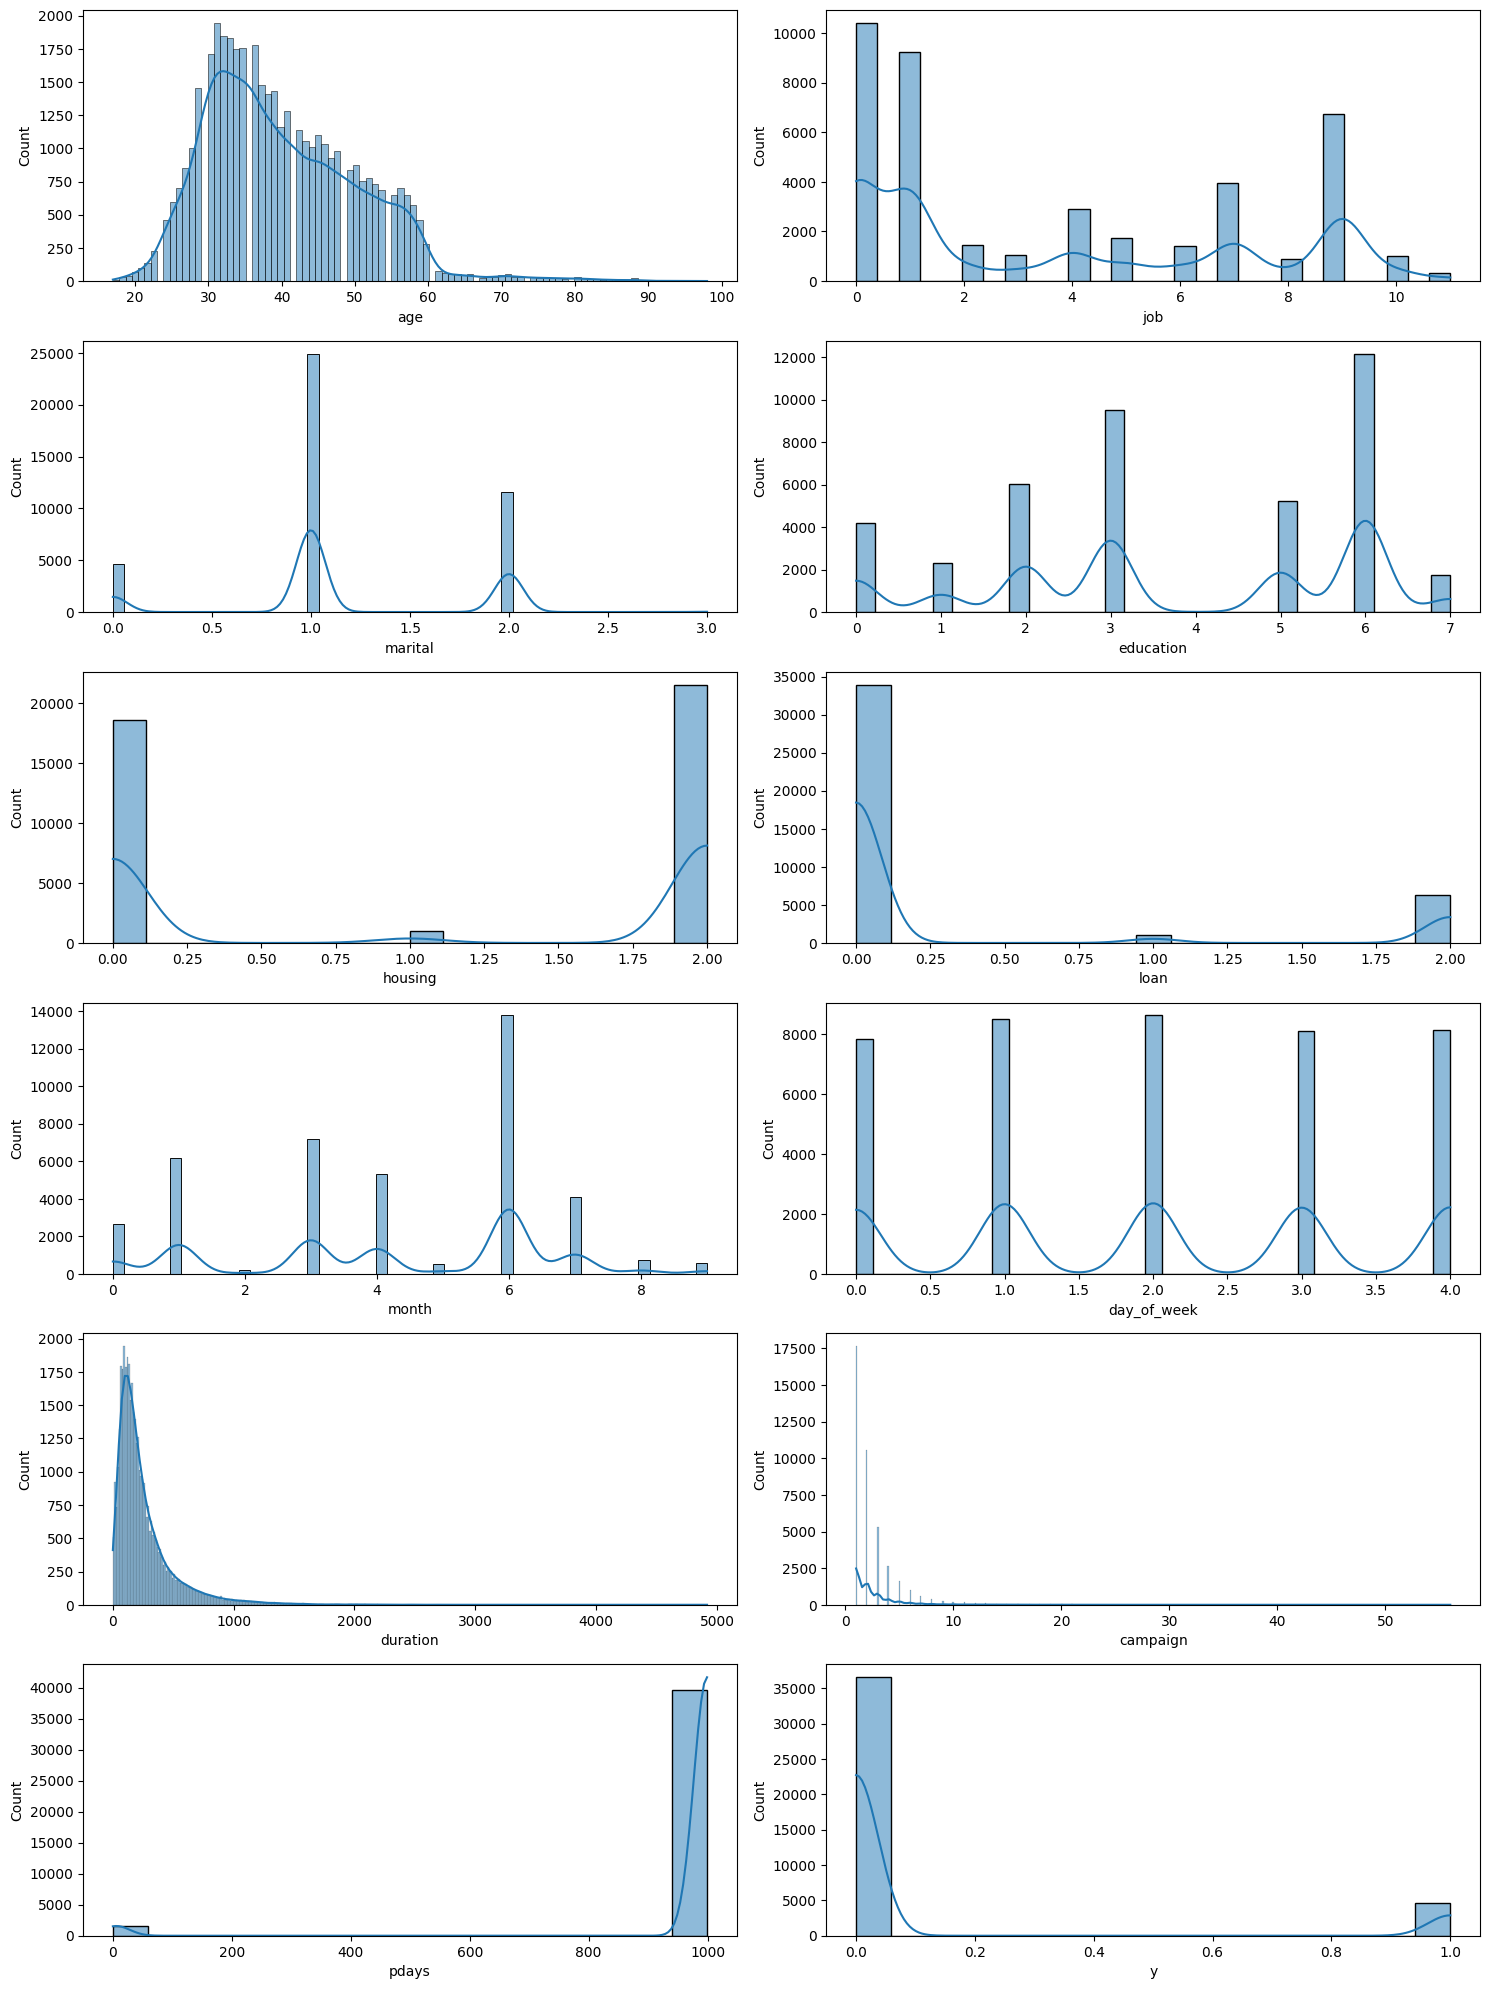

In [24]:
fig, a = plt.subplots(6, 2, figsize=(15, 20))
columns = df.columns
for i, col in enumerate(columns):
    sns.histplot(df[col], ax=a[i // 2, i % 2], kde=True)
plt.tight_layout()

In [25]:
skweness_col = ['age','duration', 'campaign']

In [26]:
df[skweness_col] = df[skweness_col].apply(lambda x: np.log1p(x))

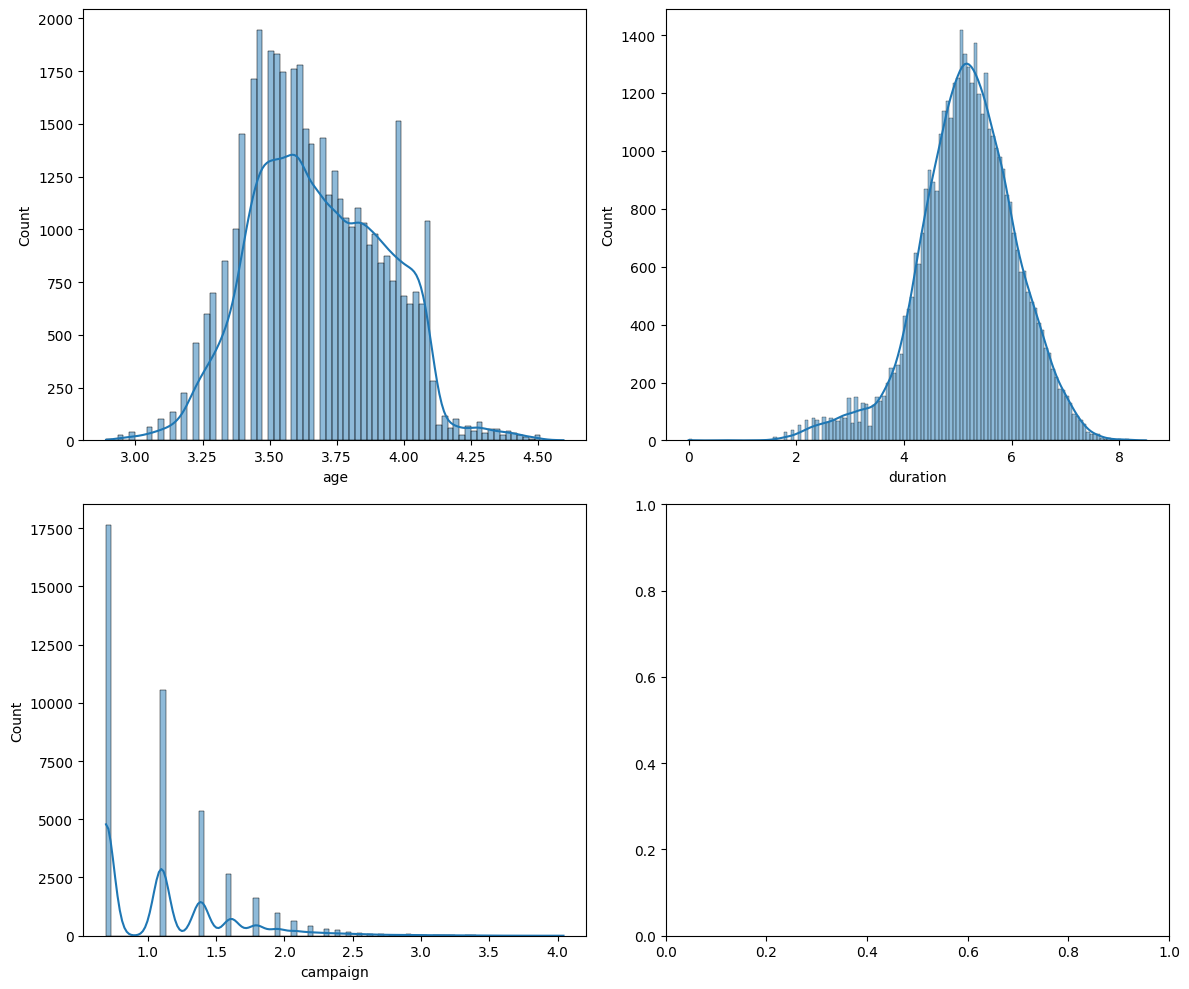

In [30]:
fig, a = plt.subplots(2, 2, figsize=(12, 10))
columns = skweness_col
for i, col in enumerate(columns):
    sns.histplot(df[col], ax=a[i // 2, i % 2], kde=True)
plt.tight_layout()

In [31]:
%pip install -q outlier-tool-shashikant

In [33]:
from outlier_tool import Outliers
o = Outliers(df)

In [35]:
o.find("iqr")

,column,method,lower,upper,outliers,percent
0,age,iqr,2.934467,4.433241,70,0.17
1,job,iqr,-10.500000,17.500000,0,0.00
2,marital,iqr,-0.500000,3.500000,0,0.00
3,education,iqr,-4.000000,12.000000,0,0.00
4,housing,iqr,-3.000000,5.000000,0,0.00
5,loan,iqr,0.000000,0.000000,7238,17.57
6,month,iqr,-1.500000,10.500000,0,0.00
7,day_of_week,iqr,-2.000000,6.000000,0,0.00
8,duration,iqr,2.934341,7.468709,985,2.39
9,campaign,iqr,-0.346574,2.426015,869,2.11


<Axes: ylabel='y'>

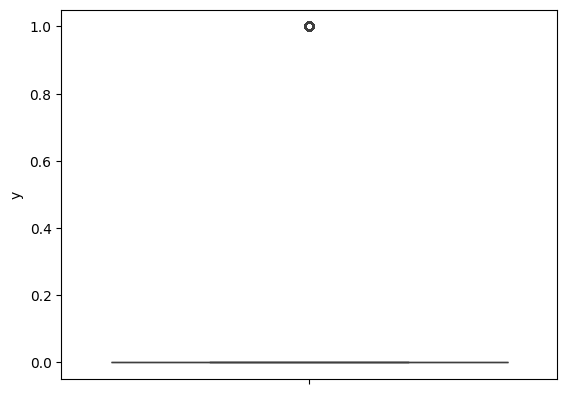

In [43]:
sns.boxplot(df['y'])

In [44]:
X = df.drop('y',axis=1)
y = df['y']

In [45]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

RFC = RandomForestClassifier()
RFC.fit(X_train, y_train)
ypred = RFC.predict(X_test)

accuracy = accuracy_score(y_test, ypred)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, ypred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, ypred)
print("Classification Report:\n", cr)

train = RFC.score(X_train, y_train)
print("Training Score:", train)

test = RFC.score(X_test, y_test)
print("Testing Score:", test)

Accuracy: 0.9055596018451081
Confusion Matrix:
 [[7083  220]
 [ 558  377]]
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.97      0.95      7303
           1       0.63      0.40      0.49       935

    accuracy                           0.91      8238
   macro avg       0.78      0.69      0.72      8238
weighted avg       0.89      0.91      0.90      8238

Training Score: 1.0
Testing Score: 0.9055596018451081


In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

RFC = RandomForestClassifier(max_depth= 3)
RFC.fit(X_train, y_train)
ypred = RFC.predict(X_test)

accuracy = accuracy_score(y_test, ypred)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, ypred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, ypred)
print("Classification Report:\n", cr)

train = RFC.score(X_train, y_train)
print("Training Score:", train)

test = RFC.score(X_test, y_test)
print("Testing Score:", test)

Accuracy: 0.8930565671279437
Confusion Matrix:
 [[7288   15]
 [ 866   69]]
Classification Report:
               precision    recall  f1-score   support

           0       0.89      1.00      0.94      7303
           1       0.82      0.07      0.14       935

    accuracy                           0.89      8238
   macro avg       0.86      0.54      0.54      8238
weighted avg       0.89      0.89      0.85      8238

Training Score: 0.8946282245827011
Testing Score: 0.8930565671279437
